# Training the Model for Pneumonet

In [2]:
from pathlib import Path

input_root = Path("/kaggle/input")

print("Searching attached Kaggle datasets...\n")

for dataset in input_root.iterdir():
    print(f"\n📁 DATASET: {dataset.name}")

    if dataset.is_dir():
        csv_files = list(dataset.rglob("*.csv"))

        if csv_files:
            for csv_file in csv_files[:30]:
                print(f"   📄 {csv_file}")
        else:
            print("   No CSV files found.")

Searching attached Kaggle datasets...


📁 DATASET: datasets
   📄 /kaggle/input/datasets/shashikalarajesh11/pneumonet-manifest-file/pneumonet_manifest (1) (1).csv
   📄 /kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/BBox_List_2017_Official_NIH.csv
   📄 /kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/Data_Entry_2017.csv


In [3]:
from pathlib import Path
import pandas as pd

# Load the recovered PneumoNet manifest
manifest_path = Path(
    "/kaggle/input/datasets/shashikalarajesh11/"
    "pneumonet-manifest-file/"
    "pneumonet_manifest (1) (1).csv"
)

df = pd.read_csv(manifest_path)

print("=" * 65)
print("PNEUMONET MANIFEST VALIDATION")
print("=" * 65)

print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

# Inspect class distribution if the expected columns exist
if {"split", "label"}.issubset(df.columns):
    print("\nClass distribution by split:")
    print(pd.crosstab(df["split"], df["label"], margins=True))

elif "label" in df.columns:
    print("\nClass distribution:")
    print(df["label"].value_counts(dropna=False))

# Inspect image path columns
path_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in ["path", "image", "file"])
]

print("\nPossible image path columns:", path_candidates)

for col in path_candidates:
    print(f"\nExamples from '{col}':")
    print(df[col].head(5).to_list())

# Check whether paths in a likely path column exist
if path_candidates:
    path_col = path_candidates[0]
    sample_paths = df[path_col].dropna().astype(str).head(10)

    print(f"\nPath existence check for '{path_col}':")

    for value in sample_paths:
        p = Path(value)
        print(f"{'FOUND' if p.is_file() else 'NOT FOUND'}: {value}")

PNEUMONET MANIFEST VALIDATION

Shape: (70727, 4)

Columns:
['image_path', 'label', 'source', 'patient_id']

First 5 rows:


,image_path,label,source,patient_id
0,/kaggle/input/datasets/unaissait/curated-chest...,COVID-19,COVID_curated,NaN
1,/kaggle/input/datasets/unaissait/curated-chest...,COVID-19,COVID_curated,NaN
2,/kaggle/input/datasets/unaissait/curated-chest...,COVID-19,COVID_curated,NaN
3,/kaggle/input/datasets/unaissait/curated-chest...,COVID-19,COVID_curated,NaN
4,/kaggle/input/datasets/unaissait/curated-chest...,COVID-19,COVID_curated,NaN



Class distribution:
label
Normal          63682
Pneumonia        4964
COVID-19         1281
Tuberculosis      800
Name: count, dtype: int64

Possible image path columns: ['image_path']

Examples from 'image_path':
['/kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curated X-Ray Dataset/COVID-19/COVID-19 (1).jpg', '/kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curated X-Ray Dataset/COVID-19/COVID-19 (10).jpg', '/kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curated X-Ray Dataset/COVID-19/COVID-19 (100).jpg', '/kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curated X-Ray Dataset/COVID-19/COVID-19 (1000).jpg', '/kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curated X-Ray Dataset/COVID-19/COVID-19 (1001).jpg']

Path existence check for 'image_path':
FOUND: /kaggle/input/datasets/unaissait/curated-chest-xray-image-dataset-for-covid19/Curat

### This checks duplicate paths, missing values, source distribution, patient-ID coverage, and whether the four classes have accessible image files.

In [4]:
from pathlib import Path
import pandas as pd

# Use the recovered manifest already loaded into df.
print("=" * 60)
print("PNEUMONET DATA QUALITY CHECK")
print("=" * 60)

# 1. Missing values
print("\n1. Missing values:")
print(df.isna().sum())

# 2. Duplicate image paths
print("\n2. Duplicate image paths:")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate image paths:", df["image_path"].duplicated().sum())

# 3. Distribution by source and class
print("\n3. Images by source and class:")
print(pd.crosstab(df["source"], df["label"], margins=True))

# 4. Patient ID coverage
print("\n4. Patient ID coverage:")
print("IDs present:", df["patient_id"].notna().sum())
print("IDs missing:", df["patient_id"].isna().sum())
print("Unique patient IDs:", df["patient_id"].nunique())

# 5. Check all image paths, not just the first ten
print("\n5. Checking image paths...")

exists = df["image_path"].map(
    lambda p: Path(str(p)).is_file() if pd.notna(p) else False
)

print("Accessible paths:", int(exists.sum()))
print("Missing paths:", int((~exists).sum()))

if (~exists).any():
    print("\nExamples of missing paths:")
    print(df.loc[~exists, "image_path"].head(10).to_list())

# 6. Label consistency
print("\n6. Labels:")
print(sorted(df["label"].dropna().unique()))

# 7. Check for existing split information in other files
print("\n7. Other potential manifest or split files:")

search_root = Path("/kaggle/input/datasets")

for p in search_root.rglob("*.csv"):
    if any(word in p.name.lower() for word in ["manifest", "split"]):
        print(p)

PNEUMONET DATA QUALITY CHECK

1. Missing values:
image_path        0
label             0
source            0
patient_id    10008
dtype: int64

2. Duplicate image paths:
Duplicate rows: 0
Duplicate image paths: 0

3. Images by source and class:
label          COVID-19  Normal  Pneumonia  Tuberculosis    All
source                                                         
COVID_curated      1281    3270       4657             0   9208
NIH                   0   60412        307             0  60719
TBX11K                0       0          0           800    800
All                1281   63682       4964           800  70727

4. Patient ID coverage:
IDs present: 60719
IDs missing: 10008
Unique patient IDs: 24952

5. Checking image paths...
Accessible paths: 70727
Missing paths: 0

6. Labels:
['COVID-19', 'Normal', 'Pneumonia', 'Tuberculosis']

7. Other potential manifest or split files:
/kaggle/input/datasets/shashikalarajesh11/pneumonet-manifest-file/pneumonet_manifest (1) (1).csv


### Step 01 : Splitting the PneumoNet dataset

#### 1.1 Why do we need to split the dataset?
Think of PneumoNet as a student learning to identify diseases from chest X-rays.

- We shouldn't teach the model using every image and then test it on those same images. That would be like giving a student the exam questions beforehand!

- Instead, we divide the dataset into three sets:

1. Training set — 80%

This is the data the model learns from. It adjusts its internal parameters to recognize patterns in chest X-rays.

2. Validation set — 10%

This helps us evaluate progress during training, compare model versions, and tune settings such as the learning rate.

3. Test set — 10%

This is held back until the end to estimate how well the final model performs on data it has not trained on.

- Our manifest contains 70,727 images, so an 80/10/10 split would give approximately 56,582 training images, 7,073 validation images, and 7,072 test images. The exact counts may differ slightly because of the splitting method.


#### 1.2 What is stratified sampling?

- Class	Number of images
Normal= 63,682
Pneumonia = 4,964
COVID-19 = 1,281
Tuberculosis = 800

- Notice the problem? Normal images make up roughly 90% of the dataset, while Tuberculosis images make up only about 1%.

Stratified sampling means dividing the data while preserving approximately the same class proportions in each split.

For example, if a dataset contains 90% Normal and 10% Pneumonia images, stratified sampling aims to keep the training, validation, and test sets close to that 90:10 ratio.

Without stratification, a small validation or test set could accidentally contain too few examples of a minority class, making evaluation unreliable.

In [5]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# Work on a copy of the recovered manifest
data = df.copy().reset_index(drop=True)
data["split"] = ""

# Separate NIH (patient IDs available) from other sources
nih = data[data["source"] == "NIH"].copy()
other = data[data["source"] != "NIH"].copy()

# 1. Split NIH by patient, so one patient cannot appear in multiple splits
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
trainval_idx, test_idx = next(
    gss_test.split(nih, groups=nih["patient_id"])
)

nih_trainval = nih.iloc[trainval_idx].copy()
nih_test = nih.iloc[test_idx].copy()
nih_test["split"] = "test"

gss_val = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=43)
train_idx, val_idx = next(
    gss_val.split(nih_trainval, groups=nih_trainval["patient_id"])
)

nih_train = nih_trainval.iloc[train_idx].copy()
nih_val = nih_trainval.iloc[val_idx].copy()

nih_train["split"] = "train"
nih_val["split"] = "val"

# 2. Stratified image-level splits for sources without patient IDs
# Stratification preserves class proportions as closely as possible.
other_trainval, other_test = train_test_split(
    other,
    test_size=0.10,
    stratify=other["label"],
    random_state=42
)

other_train, other_val = train_test_split(
    other_trainval,
    test_size=1/9,
    stratify=other_trainval["label"],
    random_state=43
)

other_train = other_train.copy()
other_val = other_val.copy()
other_test = other_test.copy()

other_train["split"] = "train"
other_val["split"] = "val"
other_test["split"] = "test"

# 3. Combine and shuffle
manifest = pd.concat(
    [
        nih_train, nih_val, nih_test,
        other_train, other_val, other_test
    ],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# 4. Validate and save
assert manifest["split"].notna().all()
assert (manifest["split"] != "").all()
assert len(manifest) == len(data)
assert manifest["image_path"].nunique() == len(manifest)

output_path = "/kaggle/working/pneumonet_split_manifest.csv"
manifest.to_csv(output_path, index=False)

print("Saved manifest:", output_path)
print("Total images:", len(manifest))

print("\nSplit sizes:")
print(manifest["split"].value_counts())

print("\nClass distribution by split:")
print(pd.crosstab(manifest["split"], manifest["label"]))

print("\nSource distribution by split:")
print(pd.crosstab(manifest["split"], manifest["source"]))

# Verify that NIH patient IDs do not cross splits
nih_with_ids = manifest[
    (manifest["source"] == "NIH") &
    manifest["patient_id"].notna()
]

patient_split_counts = nih_with_ids.groupby("patient_id")["split"].nunique()
print("\nNIH patients appearing in multiple splits:",
      int((patient_split_counts > 1).sum()))

print("\nManifest ready for the next training step.")

Saved manifest: /kaggle/working/pneumonet_split_manifest.csv
Total images: 70727

Split sizes:
split
train    56402
test      7258
val       7067
Name: count, dtype: int64

Class distribution by split:
label  COVID-19  Normal  Pneumonia  Tuberculosis
split                                           
test        128    6555        495            80
train      1025   50776       3961           640
val         128    6351        508            80

Source distribution by split:
source  COVID_curated    NIH  TBX11K
split                               
test              921   6257      80
train            7366  48396     640
val               921   6066      80

NIH patients appearing in multiple splits: 0

Manifest ready for the next training step.


### One important thing to notice

- training set contains 50,776 Normal images but only 640 Tuberculosis images.

- This is called class imbalance. A model could achieve deceptively high overall accuracy by predicting Normal too often, while missing diseases that matter.

- We'll address this during training with a class-weighted loss function, and evaluate the model using per-class recall, precision, macro F1-score, and a confusion matrix—not accuracy alone.

- Also, COVID-19 and Tuberculosis images come from different sources than most Normal images. The model might learn differences in image acquisition or dataset style rather than disease alone. We'll keep that limitation in mind when interpreting the final results.

### Check GPU availability and prepare the training environment

- Before training, we need to understand two things: what hardware we have and how the model will read the X-ray images.
#### What is a GPU, and why do we need it?
- A CPU is good at handling general-purpose tasks. A GPU can perform many numerical operations in parallel, which makes it especially useful for deep learning.

- Our model will process thousands of images and repeatedly update its parameters. A GPU can make this process substantially faster.

In [6]:

import os
import torch
import pandas as pd
from PIL import Image
from pathlib import Path

# 1. Check PyTorch and GPU
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )
else:
    print("No GPU detected. Check Kaggle notebook settings.")

# 2. Load the saved split manifest
manifest_path = Path(
    "/kaggle/working/pneumonet_split_manifest.csv"
)

assert manifest_path.exists(), (
    "Split manifest not found. Check that Step 1 completed."
)

manifest = pd.read_csv(manifest_path)

print("\nManifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())

# 3. Check class labels and split names
print("\nLabels:", sorted(manifest["label"].unique()))
print("\nSplits:")
print(manifest["split"].value_counts())

# 4. Verify that image paths exist
missing = (~manifest["image_path"].map(
    lambda p: Path(p).is_file()
)).sum()

print("\nMissing image files:", missing)

# 5. Open a sample image to verify image readability
sample_path = manifest.iloc[0]["image_path"]

with Image.open(sample_path) as img:
    print("Sample image size:", img.size)
    print("Sample image mode:", img.mode)
    img.verify()

print("Environment and sample image check completed.")


PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Manifest shape: (70727, 5)
Columns: ['image_path', 'label', 'source', 'patient_id', 'split']

Labels: ['COVID-19', 'Normal', 'Pneumonia', 'Tuberculosis']

Splits:
split
train    56402
test      7258
val       7067
Name: count, dtype: int64

Missing image files: 0
Sample image size: (224, 224)
Sample image mode: L
Environment and sample image check completed.


## Let's Understand transfer learning and load EfficientNet-B0

### Q.What is transfer learning?
- Training a deep learning model from scratch means teaching it to recognize visual patterns using only your dataset. That can take a lot of time and data.

- Transfer learning means starting with a model that has already learned useful visual features from a large image dataset, then adapting it to your specific task.

- For PneumoNet, we'll use EfficientNet-B0 with pretrained ImageNet weights.

- Pretrained EfficientNet-B0 ( Already learned general visual patterns) -->- Fine-tune for chest X-rays ( Learn patterns useful for the medical image task ) -->- Four-class output ( COVID-19 · Normal · Pneumonia · Tuberculosis )

- The pretrained model originally classifies 1,000 ImageNet categories. We'll replace its final classification layer with one that produces four output scores, one for each PneumoNet class.

- Those scores are called logits. During inference, we'll convert them into probabilities to show the model's predictions.

#### Q.What is class imbalance, and how will we handle it?
- our training set contains:
  1. Normal: 50,776 images
  2. Pneumonia: 3,961 images
  3. COVID-19: 1,025 images
  4. Tuberculosis: 640 images
- A model trained with ordinary cross-entropy loss could focus heavily on the majority class.

- We'll use class-weighted cross-entropy loss. It gives greater importance to errors on underrepresented classes. We'll calculate weights from the training split only, so validation and test labels don't influence this calculation.
- This helps address imbalance, although it doesn't guarantee good minority-class performance. We'll measure that explicitly later.

### Load the pretrained model

In [7]:

import torch
import torch.nn as nn
from torchvision import models

# 1. Select the GPU when available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

# 2. Load EfficientNet-B0 with pretrained ImageNet weights
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(weights=weights)

# 3. Replace the original 1000-class output layer with 4 classes
input_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    input_features,
    4
)

# 4. Move the model to the GPU
model = model.to(device)

# 5. Display the model configuration
print("\nModel:", model.__class__.__name__)
print("Output classes:", model.classifier[1].out_features)
print("Classifier:", model.classifier)

# Count trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

# 6. Test the model with a dummy batch
dummy_input = torch.randn(
    2, 3, 224, 224, device=device
)

model.eval()

with torch.no_grad():
    dummy_output = model(dummy_input)

print("\nTest input shape:", dummy_input.shape)
print("Test output shape:", dummy_output.shape)

assert dummy_output.shape == (2, 4)

print("\nEfficientNet-B0 is ready!")


Training device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 220MB/s]



Model: EfficientNet
Output classes: 4
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)

Total parameters: 4,012,672
Trainable parameters: 4,012,672

Test input shape: torch.Size([2, 3, 224, 224])
Test output shape: torch.Size([2, 4])

EfficientNet-B0 is ready!


### Configure the training process

#### Q.how does model training work?
- Imagine PneumoNet receives a chest X-ray whose correct label is Pneumonia.
1. Forward pass: EfficientNet looks at the image and produces four scores: COVID-19, Normal, Pneumonia, and Tuberculosis.
2. Loss calculation: We compare the scores with the correct label. A higher loss generally means the prediction was worse.
3. Backpropagation: The model calculates how its parameters contributed to the error.
4. Optimizer update: The optimizer adjusts the parameters to reduce future errors.
5. Repeat: We process batches of images until an epoch is complete.
- An epoch means one pass through the entire training dataset. Since we have 56,402 training images and a batch size of 32, one epoch requires approximately 1,763 batches.

We'll begin with a conservative fine-tuning configuration rather than training for dozens of epochs blindly.

#### Handle class imbalance using weighted loss
- our Normal class has far more images than the Tuberculosis class. We'll calculate a weight for each class using:

- wc= N/(C * n_c)

- Where:
- \(N\) = total training images
- \(C\) = number of classes (4)
- \(n_c\) = number of training images in class \(c\)

- 
A class with fewer images receives a higher weight, so mistakes on that class contribute more to the loss.

### Configure the optimizer and training settings

- The optimizer determines how the model's parameters are updated. We'll use AdamW, a widely used optimizer that combines adaptive learning rates with weight decay.

- The learning rate controls the size of each update. We'll start with 0.0001 because we're fine-tuning a pretrained model; excessively large updates could damage the useful features it has already learned.

- We'll also use mixed-precision training, which can speed up computation and reduce GPU memory usage on your Tesla T4.

In [9]:

import pandas as pd
from pathlib import Path
from collections import Counter

# Load the split manifest saved earlier
manifest_path = Path(
    "/kaggle/working/pneumonet_split_manifest.csv"
)

assert manifest_path.exists(), (
    "Split manifest is missing. Check the saved file path."
)

manifest = pd.read_csv(manifest_path)

# Recreate the three DataFrames
train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "val"].copy()
test_df = manifest[manifest["split"] == "test"].copy()

# Confirm the restored variables
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining class counts:")
print(train_df["label"].value_counts())

print("\nVariables restored successfully!")


Training images: 56402
Validation images: 7067
Test images: 7258

Training class counts:
label
Normal          50776
Pneumonia        3961
COVID-19         1025
Tuberculosis      640
Name: count, dtype: int64

Variables restored successfully!


In [11]:

# Keep this order consistent with the model's four output neurons
class_names = [
    "COVID-19",
    "Normal",
    "Pneumonia",
    "Tuberculosis"
]

class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

print("Class names:", class_names)
print("Class mapping:", class_to_idx)


Class names: ['COVID-19', 'Normal', 'Pneumonia', 'Tuberculosis']
Class mapping: {'COVID-19': 0, 'Normal': 1, 'Pneumonia': 2, 'Tuberculosis': 3}


In [12]:

import torch
import torch.nn as nn
from collections import Counter
from pathlib import Path

# 1. Training configuration
NUM_EPOCHS = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
CHECKPOINT_DIR = Path("/kaggle/working/pneumonet_checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Calculate class weights using ONLY the training labels
train_counts = Counter(train_df["label"])

counts = torch.tensor(
    [train_counts[name] for name in class_names],
    dtype=torch.float32
)

num_classes = len(class_names)
total_train = counts.sum()

class_weights = total_train / (num_classes * counts)

# Normalize weights to have a mean of 1
class_weights = class_weights / class_weights.mean()

class_weights = class_weights.to(device)

print("Training class counts:")
for name, count in zip(class_names, counts.tolist()):
    print(f"  {name}: {int(count)}")

print("\nClass weights:")
for name, weight in zip(class_names, class_weights.tolist()):
    print(f"  {name}: {weight:.3f}")

# 3. Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(weight=class_weights)

# 4. AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 5. Learning-rate scheduler
# The training loop will step this using validation macro F1.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

# 6. Enable mixed precision only when running on CUDA
USE_AMP = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("\nEpochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Mixed precision:", USE_AMP)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("\nTraining configuration ready!")


Training class counts:
  COVID-19: 1025
  Normal: 50776
  Pneumonia: 3961
  Tuberculosis: 640

Class weights:
  COVID-19: 1.389
  Normal: 0.028
  Pneumonia: 0.359
  Tuberculosis: 2.224

Epochs: 5
Learning rate: 0.0001
Weight decay: 0.0001
Mixed precision: True
Checkpoint directory: /kaggle/working/pneumonet_checkpoints

Training configuration ready!


#### Q. What do the class weights mean?
- The weights are normalized to have an average of 1. Therefore, Tuberculosis errors receive much more weight than Normal errors.

- This helps the model pay attention to underrepresented classes. However, a large weight doesn't automatically make the model accurate, and excessive weighting can increase false positives. We'll check the per-class metrics after training.

#### Q.What will happen during training?
- For each epoch, the model will:
1. Read batches of 32 training images.
2. Predict the four classes.
3. Calculate the weighted cross-entropy loss.
4. Update its parameters using backpropagation and AdamW.
5. Evaluate on the validation set.
6. Save a checkpoint whenever validation macro F1 improves.
- We'll use validation macro F1 to select the best checkpoint and adjust the learning rate. The test set remains untouched.

### Restore the DataLoaders
- A Dataset knows how to load one image and its label. A DataLoader groups those images into batches of 32 and feeds them to the GPU.

In [14]:

import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# 1. Restore manifest and split DataFrames
manifest_path = Path(
    "/kaggle/working/pneumonet_split_manifest.csv"
)
assert manifest_path.exists(), "Split manifest not found."

manifest = pd.read_csv(manifest_path)

train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "val"].copy()
test_df = manifest[manifest["split"] == "test"].copy()

# 2. Restore class mapping if necessary
class_names = [
    "COVID-19",
    "Normal",
    "Pneumonia",
    "Tuberculosis"
]
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

# 3. Recreate the image transformations
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Recreate the Dataset class
class PneumoNetDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["label"]]
        return image, label

# 5. Recreate the three datasets
train_dataset = PneumoNetDataset(train_df, image_transform)
val_dataset = PneumoNetDataset(val_df, image_transform)
test_dataset = PneumoNetDataset(test_df, image_transform)

# 6. Create the DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 7. Verify that the pipeline works
images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Batch shape:", images.shape)
print("Label shape:", labels.shape)
print("DataLoaders restored successfully!")


Training images: 56402
Validation images: 7067
Test images: 7258
Batch shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
DataLoaders restored successfully!


### Run the training loop

In [15]:

import copy
import time
import numpy as np
import torch
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# Verify required objects before starting
required = [
    "model", "device", "train_loader", "val_loader",
    "criterion", "optimizer", "scheduler", "scaler",
    "USE_AMP", "NUM_EPOCHS", "CHECKPOINT_DIR"
]

missing = [name for name in required if name not in globals()]
assert not missing, (
    f"Missing variables: {missing}. Rerun their setup cells first."
)

CHECKPOINT_DIR = Path(CHECKPOINT_DIR)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

best_val_f1 = -1.0
best_epoch = 0
history = []
patience = 2
epochs_without_improvement = 0

# Evaluate the model on validation data
def evaluate_model(model, loader):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predictions.cpu().numpy())

    avg_loss = total_loss / total_samples

    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro",
        zero_division=0
    )
    macro_recall = recall_score(
        all_labels, all_preds,
        average="macro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "macro_recall": macro_recall,
        "labels": all_labels,
        "predictions": all_preds
    }


# Train for up to NUM_EPOCHS epochs
for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()
    model.train()

    running_loss = 0.0
    samples_seen = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        samples_seen += batch_size

        if (batch_idx + 1) % 200 == 0:
            print(
                f"Epoch {epoch}/{NUM_EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = running_loss / samples_seen

    # Validation is used for model selection
    val_metrics = evaluate_model(model, val_loader)

    scheduler.step(val_metrics["macro_f1"])

    elapsed = time.time() - start_time

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_macro_recall": val_metrics["macro_recall"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "seconds": elapsed
    }
    history.append(record)

    print(f"\nEpoch {epoch}/{NUM_EPOCHS} completed")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_metrics['loss']:.4f}")
    print(f"Validation accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Validation macro F1: {val_metrics['macro_f1']:.4f}")
    print(f"Validation macro recall: {val_metrics['macro_recall']:.4f}")
    print(f"Time: {elapsed / 60:.1f} minutes\n")

    # Save the best checkpoint according to validation macro F1
    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "class_names": class_names
            },
            CHECKPOINT_DIR / "best_pneumonet.pth"
        )

        print("Saved new best model checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: validation macro F1 did not improve.")
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print(f"Best validation macro F1: {best_val_f1:.4f}")
print("Checkpoint:", CHECKPOINT_DIR / "best_pneumonet.pth")


Epoch 1/5 | Batch 200/1763 | Loss: 0.2316
Epoch 1/5 | Batch 400/1763 | Loss: 0.6497
Epoch 1/5 | Batch 600/1763 | Loss: 0.2393
Epoch 1/5 | Batch 800/1763 | Loss: 0.1816
Epoch 1/5 | Batch 1000/1763 | Loss: 0.0781
Epoch 1/5 | Batch 1200/1763 | Loss: 0.0454
Epoch 1/5 | Batch 1400/1763 | Loss: 0.0310
Epoch 1/5 | Batch 1600/1763 | Loss: 0.0619

Epoch 1/5 completed
Training loss: 0.2893
Validation loss: 0.2010
Validation accuracy: 0.9717
Validation macro F1: 0.8682
Validation macro recall: 0.9529
Time: 9.1 minutes

Saved new best model checkpoint.
Epoch 2/5 | Batch 200/1763 | Loss: 0.0118
Epoch 2/5 | Batch 400/1763 | Loss: 0.0407
Epoch 2/5 | Batch 600/1763 | Loss: 0.0871
Epoch 2/5 | Batch 800/1763 | Loss: 0.1061
Epoch 2/5 | Batch 1000/1763 | Loss: 0.0789
Epoch 2/5 | Batch 1200/1763 | Loss: 0.0404
Epoch 2/5 | Batch 1400/1763 | Loss: 0.0137
Epoch 2/5 | Batch 1600/1763 | Loss: 0.0113

Epoch 2/5 completed
Training loss: 0.1274
Validation loss: 0.2014
Validation accuracy: 0.9757
Validation macro F

### test-set evaluation

-Load the best checkpoint and evaluate

In [16]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Load the best saved model
checkpoint_path = (
    "/kaggle/working/pneumonet_checkpoints/"
    "best_pneumonet.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best epoch:", checkpoint["epoch"])
print("Best validation macro F1:",
      checkpoint["best_val_macro_f1"])

# Generate predictions on the test set
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_labels.extend(labels.numpy())

# Calculate metrics
accuracy = accuracy_score(
    all_labels, all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("\n========== PNEUMONET TEST RESULTS ==========")
print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1 Score:  {f1:.4f}")

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\nCONFUSION MATRIX:\n")
display(cm_df)

Loaded best epoch: 5
Best validation macro F1: 0.9455890608821831

========== PNEUMONET TEST RESULTS ==========
Test Accuracy:  0.9848
Macro Precision: 0.9095
Macro Recall:    0.9627
Macro F1 Score:  0.9347

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

    COVID-19     0.8652    0.9531    0.9071       128
      Normal     0.9948    0.9895    0.9921      6555
   Pneumonia     0.9112    0.9333    0.9222       495
Tuberculosis     0.8667    0.9750    0.9176        80

    accuracy                         0.9848      7258
   macro avg     0.9095    0.9627    0.9347      7258
weighted avg     0.9854    0.9848    0.9850      7258


CONFUSION MATRIX:



,COVID-19,Normal,Pneumonia,Tuberculosis
COVID-19,122,3,0,3
Normal,16,6486,45,8
Pneumonia,2,30,462,1
Tuberculosis,1,1,0,78


### EfficientNet-B0 model achieved 98.48% test accuracy and 93.47% macro F1-score on 7,258 test images

### Save all evaluation results

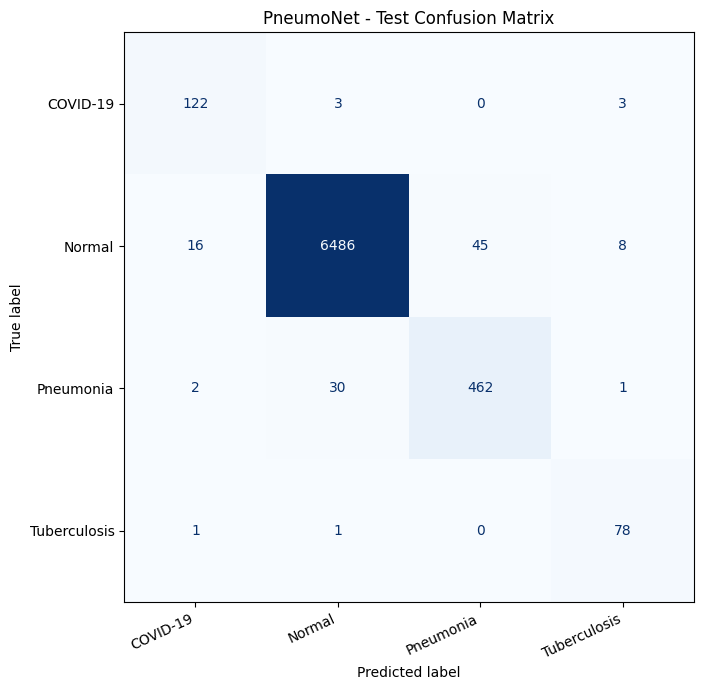

All evaluation artifacts saved!

Files created:
best_pneumonet.pth: 47496.6 KB
classification_report.csv: 0.5 KB
confusion_matrix.csv: 0.1 KB
confusion_matrix.png: 80.8 KB
metrics.json: 0.4 KB
model_config.json: 0.5 KB


In [17]:

from pathlib import Path
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create output folder
OUTPUT_DIR = Path("/kaggle/working/pneumonet_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Generate the detailed classification report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

# 2. Save the confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(OUTPUT_DIR / "confusion_matrix.csv")

# 3. Create a confusion matrix image
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("PneumoNet - Test Confusion Matrix")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 4. Save summary metrics
metrics = {
    "model": "EfficientNet-B0",
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "test_accuracy": float(accuracy),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "test_images": int(len(all_labels)),
    "class_names": class_names
}

with open(OUTPUT_DIR / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

# 5. Copy trained checkpoint into results folder
checkpoint_source = Path(
    "/kaggle/working/pneumonet_checkpoints/"
    "best_pneumonet.pth"
)

assert checkpoint_source.exists(), (
    f"Checkpoint not found: {checkpoint_source}"
)

shutil.copy2(
    checkpoint_source,
    OUTPUT_DIR / "best_pneumonet.pth"
)

# 6. Save preprocessing and model configuration
config = {
    "architecture": "efficientnet_b0",
    "num_classes": 4,
    "class_names": class_names,
    "input_size": [224, 224],
    "input_channels": 3,
    "color_mode": "RGB",
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "training_epochs": 5,
    "batch_size": 32,
    "learning_rate": 0.0001
}

with open(OUTPUT_DIR / "model_config.json", "w") as file:
    json.dump(config, file, indent=4)

print("All evaluation artifacts saved!")
print("\nFiles created:")

for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size / 1024:.1f} KB")


### Create a downloadable ZIP

In [18]:

import zipfile
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/pneumonet_results")
ZIP_PATH = Path("/kaggle/working/pneumonet_artifacts.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zipf:

    for file in OUTPUT_DIR.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)

print("ZIP created:", ZIP_PATH)
print("ZIP size: {:.2f} MB".format(
    ZIP_PATH.stat().st_size / (1024 * 1024)
))


ZIP created: /kaggle/working/pneumonet_artifacts.zip
ZIP size: 42.68 MB


### Verify the final artifacts

In [19]:

from pathlib import Path
import json

folder = Path("/kaggle/working/pneumonet_results")

required_files = [
    "best_pneumonet.pth",
    "metrics.json",
    "classification_report.csv",
    "confusion_matrix.csv",
    "confusion_matrix.png",
    "model_config.json"
]

for name in required_files:
    path = folder / name
    print(
        f"{'OK' if path.exists() and path.stat().st_size > 0 else 'MISSING'}"
        f" - {name}"
    )

with open(folder / "metrics.json") as file:
    saved_metrics = json.load(file)

print("\nSaved test accuracy:",
      f"{saved_metrics['test_accuracy']:.2%}")
print("Saved test macro F1:",
      f"{saved_metrics['test_macro_f1']:.2%}")


OK - best_pneumonet.pth
OK - metrics.json
OK - classification_report.csv
OK - confusion_matrix.csv
OK - confusion_matrix.png
OK - model_config.json

Saved test accuracy: 98.48%
Saved test macro F1: 93.47%


### Download the model

In [20]:

from pathlib import Path
import shutil

model_path = Path(
    "/kaggle/working/pneumonet_results/best_pneumonet.pth"
)

assert model_path.exists(), "Trained model checkpoint not found!"

download_path = shutil.make_archive(
    "/kaggle/working/pneumonet_model",
    "zip",
    root_dir=model_path.parent,
    base_dir=model_path.name
)

print("Model ZIP created:", download_path)
print("ZIP size:", round(Path(download_path).stat().st_size / (1024 * 1024), 2), "MB")


Model ZIP created: /kaggle/working/pneumonet_model.zip
ZIP size: 42.62 MB


### Test one X-ray in your Kaggle notebook

In [21]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import pandas as pd
from pathlib import Path

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Load checkpoint
CHECKPOINT_PATH = "/kaggle/working/pneumonet_checkpoints/best_pneumonet.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# 3. Rebuild the same model architecture
class_names = ["COVID-19", "Normal", "Pneumonia", "Tuberculosis"]

model = models.efficientnet_b0(weights=None)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, len(class_names))

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# 4. Image preprocessing (same as validation/test)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 5. Select one test image from the manifest
manifest = pd.read_csv("/kaggle/working/pneumonet_split_manifest.csv")
test_row = manifest[manifest["split"] == "test"].sample(1, random_state=42).iloc[0]

image_path = test_row["image_path"]
actual_label = test_row["label"]

# 6. Predict
image = Image.open(image_path).convert("RGB")
image_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(image_tensor)
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_label = class_names[predicted_index]

print("Actual label:   ", actual_label)
print("Predicted label:", predicted_label)
print("\nModel scores (not clinically calibrated):")

for name, score in zip(class_names, probabilities.cpu().tolist()):
    print(f"{name:15s}: {score:.4f}")

Actual label:    Normal
Predicted label: Normal

Model scores (not clinically calibrated):
COVID-19       : 0.0000
Normal         : 0.9994
Pneumonia      : 0.0006
Tuberculosis   : 0.0000


### Another test

In [22]:

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import pandas as pd

# Class order must match training
class_names = ["COVID-19", "Normal", "Pneumonia", "Tuberculosis"]

# Load trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/kaggle/working/pneumonet_checkpoints/best_pneumonet.pth",
    map_location=device,
    weights_only=True
)

model = models.efficientnet_b0(weights=None)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, len(class_names))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Same preprocessing used during evaluation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load test manifest
manifest = pd.read_csv(
    "/kaggle/working/pneumonet_split_manifest.csv"
)
test_df = manifest[manifest["split"] == "test"]

# Test one image from each class
for actual_label in class_names:
    sample = test_df[test_df["label"] == actual_label].sample(
        n=1, random_state=42
    ).iloc[0]

    image = Image.open(sample["image_path"]).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        probabilities = torch.softmax(model(tensor), dim=1)[0]

    predicted_idx = probabilities.argmax().item()
    predicted_label = class_names[predicted_idx]

    print("=" * 45)
    print("Actual label:   ", actual_label)
    print("Predicted label:", predicted_label)
    print("Result:         ", 
          "CORRECT" if predicted_label == actual_label else "INCORRECT")

    for name, score in zip(class_names, probabilities.cpu().tolist()):
        print(f"  {name:15s}: {score:.4f}")


Actual label:    COVID-19
Predicted label: COVID-19
Result:          CORRECT
  COVID-19       : 0.9861
  Normal         : 0.0137
  Pneumonia      : 0.0001
  Tuberculosis   : 0.0000
Actual label:    Normal
Predicted label: Normal
Result:          CORRECT
  COVID-19       : 0.0000
  Normal         : 0.9980
  Pneumonia      : 0.0020
  Tuberculosis   : 0.0000
Actual label:    Pneumonia
Predicted label: Pneumonia
Result:          CORRECT
  COVID-19       : 0.0000
  Normal         : 0.0001
  Pneumonia      : 0.9999
  Tuberculosis   : 0.0000
Actual label:    Tuberculosis
Predicted label: Tuberculosis
Result:          CORRECT
  COVID-19       : 0.0009
  Normal         : 0.0099
  Pneumonia      : 0.0089
  Tuberculosis   : 0.9804
